# 5-01 아무 데이터나 조회 — 시세·지수·순위·밸류에이션·재무를 표와 CSV로

**질문 예시:** "삼성전자 최근 한 달 일별 시세랑 거래량 뽑아줘", "코스피 거래대금 상위 20종목", "반도체 3사 종가 나란히",
"삼성전자 PER·PBR 추이", "삼성전자 최근 분기 실적", "CSV로 저장해줘"

CHECK 원본(`5_데이터조회/01_아무데이터나조회`)과 같은 "그냥 데이터 좀 줘" 시나리오입니다. DeepSearch로 되는 것과 안 되는 것은 아래와 같습니다.

| 분류 | DeepSearch | 함수 |
|---|---|---|
| 종목 일별 시세·거래량·시가총액 | ✅ | `GetStockPrices` |
| 여러 종목 한 번에 | ✅ | `GetStockPrices([...])` |
| 지수(코스피·코스닥 계열 11종) | ✅ | `GetMarketIndexes` |
| 거래대금·등락률·시총 순위 | ✅ 전 종목 하루치를 받아 정렬 | `GetStockPrices` (종목 생략) |
| PER·PBR·배당수익률 | ✅ CHECK에선 일별 필드가 없던 항목 | 자연어 질의 `삼성전자 PER PBR 기간` |
| 분기·연간 재무 | ✅ | `GetFinancialStatements` |
| 환율·미국 금리 | ✅ FRED | `QueryFredSeriesData` |
| **외국인 보유율·투자자 수급·선물·ETF NAV·국고채** | ❌ 없음 | `research/data_gaps` |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/5_data_lookup/01_any_data.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
START = "2026-10-24"   # 약 1개월

## 1. 한 종목 일별 시세
`KRX:종목코드`로 지정합니다. 이름만 알면 5-02 노트북처럼 `universe()`에서 코드를 찾습니다.

In [4]:
px = stock_prices("KRX:005930", START, ASOF)
px = px.assign(등락률=(px["change_rate"] * 100).round(2))[
    ["date", "open", "high", "low", "close", "등락률", "volume", "value", "market_cap"]]
px.columns = ["일자", "시가", "고가", "저가", "종가", "등락률(%)", "거래량", "거래대금(원)", "시가총액(원)"]
print(PRICE_NOTICE)
px.tail(10)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


,일자,시가,고가,저가,종가,등락률(%),거래량,거래대금(원),시가총액(원)
12,2026-11-11,197100,206500,196300,206000,3.57,15587917,3155650209961,1204333393248000
13,2026-11-12,208500,214000,206000,208000,0.97,19089501,3995766552115,1216025950464000
14,2026-11-13,214000,216000,205000,206000,-0.96,12319571,2582658244000,1204333393248000
15,2026-11-16,206500,208000,195000,196800,-4.47,15581820,3111946930796,1150547630054400
16,2026-11-17,191400,195900,190100,190300,-3.30,16060824,3083762252994,1112546819102400
17,2026-11-18,196900,199950,188800,194700,2.31,17104342,3315772410300,1138270444977600
18,2026-11-19,196000,196900,189800,196900,1.13,12308271,2384827849400,1151132257915200
19,2026-11-20,188100,189300,181400,183100,-7.01,16662829,3077590105300,1070453613124800
20,2026-11-23,177600,179600,171500,177500,-3.06,18700901,3296778337814,1037714452920000
21,2026-11-24,193200,193700,187500,189400,6.70,15699501,3000636004700,1107285168355200


## 2. 여러 종목 종가 나란히
종목 목록을 한 번에 넣으면 한 번의 호출로 옵니다.

symbol,삼성전자,SK하이닉스,한미반도체
date,,,
2026-11-18,194700,1144000,167700
2026-11-19,196900,1183000,172400
2026-11-20,183100,1113000,153800
2026-11-23,177500,1085000,150800
2026-11-24,189400,1158000,163600


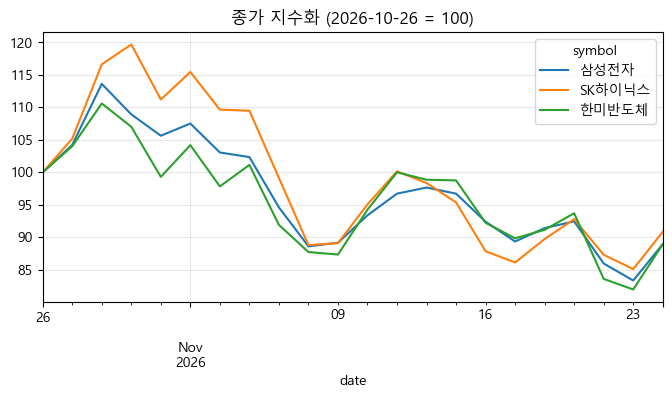

In [5]:
names = {"KRX:005930": "삼성전자", "KRX:000660": "SK하이닉스", "KRX:042700": "한미반도체"}
multi = stock_prices(list(names), START, ASOF, columns=["close"])
wide = multi.pivot(index="date", columns="symbol", values="close")[list(names)].rename(columns=names)
display(wide.tail(5))
ax = (wide / wide.iloc[0] * 100).plot(figsize=(8, 3.5), title=f"종가 지수화 ({wide.index[0].date()} = 100)")
ax.grid(alpha=.3)

## 3. 지수
지수 `change_rate`는 퍼센트, `value`는 백만원 단위입니다.

In [6]:
ix = index_prices(START, ASOF)
kospi = ix[ix["symbol"] == "KRX:KOSPI"][["date", "close", "change", "change_rate", "value"]].copy()
kospi["거래대금"] = (kospi["value"] * 1e6).map(krw)
kospi.drop(columns="value").tail(5)

,date,close,change,change_rate,거래대금
191,2026-11-18,5067.44,98.96,1.99,15.7조
202,2026-11-19,5137.89,70.45,1.39,13.4조
213,2026-11-20,4869.96,-267.93,-5.21,14.9조
224,2026-11-23,4708.54,-161.42,-3.31,16.1조
235,2026-11-24,5006.03,297.49,6.32,15.8조


## 4. 순위 — 코스피 거래대금 상위 20
종목을 지정하지 않으면 **전 종목 하루치**가 한 번에 옵니다. ETF가 거래대금 상위를 차지하므로 기본은 일반 종목만 보고,
ETF 포함 순위도 함께 보여 줍니다.

In [7]:
allx = all_stocks(ASOF, common_only=False)
allx = allx[allx["date"] == allx["date"].max()]
def rank(df, n=20):
    out = df.nlargest(n, "value")
    return pd.DataFrame({"종목": out["name"], "종가": out["close"].map("{:,.0f}".format),
                         "등락률(%)": (out["change_rate"] * 100).round(2), "거래대금": out["value"].map(krw)}).reset_index(drop=True)
kospi_all = allx[allx["market"] == "KOSPI"]
print("기준일:", allx["date"].max().date())
print("[일반 종목만 (ETF·ETN 제외)]"); display(rank(kospi_all[kospi_all["company_type_l1"] != "8"]))
print("[ETF 포함 상위 10]"); display(rank(kospi_all, 10))

기준일: 2026-11-24
[일반 종목만 (ETF·ETN 제외)]


,종목,종가,등락률(%),거래대금
0,SK하이닉스,"1,158,000",6.73,3.9조
1,삼성전자,"189,400",6.70,3.0조
2,삼성전기,"858,000",10.28,"6,675억"
3,삼성전자우,"150,100",6.53,"4,581억"
4,SK스퀘어,"715,000",5.15,"4,165억"
5,삼성SDI,"450,000",13.64,"3,193억"
6,현대차,"275,000",11.11,"1,842억"
7,LG전자,"143,200",15.86,"1,831억"
8,삼성E&A,"59,700",7.57,"1,359억"
9,기아,"95,600",10.65,"1,340억"


[ETF 포함 상위 10]


,종목,종가,등락률(%),거래대금
0,SK하이닉스,"1,158,000",6.73,3.9조
1,삼성전자,"189,400",6.70,3.0조
2,KODEX 200,"78,660",6.63,1.7조
3,KODEX 레버리지,"52,935",13.63,1.4조
4,KODEX 인버스,"1,330",-6.80,1.3조
5,KODEX 200선물인버스2X,121,-13.57,1.2조
6,TIGER 미국S&P500,"24,140",2.35,"7,328억"
7,삼성전기,"858,000",10.28,"6,675억"
8,TIGER 200,"78,440",6.79,"6,515억"
9,KODEX 미국S&P500,"21,880",2.41,"6,215억"


## 5. PER·PBR·배당수익률
자연어 질의(`종목 지표 기간`)로 받습니다. 결과 컬럼 이름에 질의 문구가 붙어 나오므로 정리해서 씁니다.
- PER = 시가총액 ÷ 당기순이익, PBR = 시가총액 ÷ 자본(지배지분). FY N 값이 N+1년 첫 거래일부터 쓰입니다(`research/pbr_bps`).
- 배당수익률 단위는 %입니다.

In [8]:
def nl(query):
    df = ds_df(query)
    df.columns = [c.split(" ")[0] if " 20" in c else c for c in df.columns]   # "PER 2026-11-18-…" → "PER"
    return df

val = nl(f"삼성전자 PER PBR {START}-{ASOF}")
display(val.tail(5))
peer = nl(f"삼성전자 SK하이닉스 한미반도체 PER PBR 배당수익률 {ASOF}-{ASOF}")
peer

,date,symbol,entity_name,PER,PBR
18,2026-11-18,KRX:005930,삼성전자,29.480000,3.04
19,2026-11-19,KRX:005930,삼성전자,29.809999,3.08
20,2026-11-20,KRX:005930,삼성전자,27.719999,2.86
21,2026-11-23,KRX:005930,삼성전자,26.870001,2.77
22,2026-11-24,KRX:005930,삼성전자,28.680000,2.96


,date,symbol,entity_name,PER,PBR,배당수익률
0,2026-11-24,KRX:000660,SK하이닉스,18.660000,6.74,0.276498
1,2026-11-24,KRX:005930,삼성전자,28.680000,2.96,0.939718
2,2026-11-24,KRX:042700,한미반도체,72.519997,22.48,0.530504


전 종목 PER도 한 번에 받을 수 있습니다(`상장 기업 and PER 날짜`, 4,000여 행). 아래는 시가총액 1조 원 이상 보통주 중 PER이 낮은 종목입니다
(적자 기업은 PER이 음수라 뺐고, 우선주는 뺐습니다). PER이 아주 낮으면 일회성 이익 때문일 수 있으니 실적을 함께 보세요.

In [9]:
per_all = nl(f"상장 기업 and PER {ASOF}")
per_all = per_all.merge(allx[["symbol", "market", "market_cap", "company_type_l1"]], on="symbol")
low = per_all[(per_all["company_type_l1"] == "1") & per_all["symbol"].str.endswith("0") & (per_all["market_cap"] >= 1e12) & (per_all["PER"] > 0)].nsmallest(10, "PER")
low.assign(시가총액=low["market_cap"].map(krw))[["entity_name", "market", "PER", "시가총액"]].reset_index(drop=True)

,entity_name,market,PER,시가총액
0,KCC,KOSPI,1.67,3.0조
1,맥쿼리인프라,KOSPI,2.35,4.6조
2,다우기술,KOSPI,2.55,1.3조
3,현대해상,KOSPI,2.56,2.8조
4,HDC,KOSPI,3.17,1.1조
5,동원산업,KOSPI,3.53,1.4조
6,한국금융지주,KOSPI,3.68,7.1조
7,현대지에프홀딩스,KOSPI,4.23,2.1조
8,금호타이어,KOSPI,4.25,1.5조
9,하림지주,KOSDAQ,4.26,1.1조


## 6. 재무 — 분기 실적
`GetFinancialStatements`의 계정 이름은 매출액이 `수익`, 영업이익이 `영업이익(손실)`, 지배주주 순이익이 `당기순이익지배기업지분`입니다.
`is_accumulated=False`(기본)이면 분기 3개월 값입니다.

In [10]:
fs = ds_df(f'GetFinancialStatements(삼성전자, report_type="IFRS", consolidated=True, is_annual=False, '
           f'report_ids="Income", date_from=2025-01-01, date_to={ASOF})')
ACC = {"수익": "매출액", "영업이익(손실)": "영업이익", "당기순이익지배기업지분": "지배순이익"}
q = fs[fs["name_ko"].isin(ACC)].pivot_table(index="date", columns="name_ko", values="value").rename(columns=ACC)
q = (q[list(ACC.values())] / 1e12).round(2)
q["영업이익률(%)"] = (q["영업이익"] / q["매출액"] * 100).round(1)
q.index = q.index.strftime("%Y-%m")
print("단위: 조원 (연결, 분기 3개월)")
q

단위: 조원 (연결, 분기 3개월)


name_ko,매출액,영업이익,지배순이익,영업이익률(%)
date,,,,
2025-03,79.14,6.69,8.03,8.5
2025-06,74.57,4.68,4.93,6.3
2025-09,86.06,12.17,12.01,14.1
2025-12,93.84,20.07,19.29,21.4
2026-03,133.87,57.23,47.10,42.8
2026-06,171.50,89.49,71.27,52.2
2026-09,195.25,107.44,75.21,55.0


## 7. CSV로 저장
Colab에서는 저장한 파일을 바로 내려받습니다. 로컬에서는 현재 폴더에 저장됩니다.

In [11]:
out = "samsung_daily.csv"
px.to_csv(out, index=False, encoding="utf-8-sig")   # 엑셀에서 한글이 깨지지 않게 utf-8-sig
print("저장:", out, f"({len(px)}행)")
if IN_COLAB:
    from google.colab import files
    files.download(out)
else:
    import os
    os.remove(out)   # 로컬 빌드에서는 남기지 않음

저장: samsung_daily.csv (22행)


## 없는 데이터
외국인 보유율, 투자자별 수급, 공매도·대차·신용, 지수선물, ETF NAV, 국고채 금리는 DeepSearch에 없습니다.
자연어로 물으면 오류 없이 **기업 개요 표**가 돌아오니, 결과 컬럼을 꼭 확인하세요(근거: `research/data_gaps`).

In [12]:
chk = ds_df(f"삼성전자 외국인보유비율 {START}-{ASOF}")
print("'외국인보유비율' 질의 결과 컬럼:", list(chk.columns)[:6], "… →", "기업 개요 표(데이터 없음)" if "ceo" in chk.columns else "데이터 있음")

'외국인보유비율' 질의 결과 컬럼: ['symbol', 'entity_name', 'symbol_nice', 'ceo', 'business_rid', 'company_rid'] … → 기업 개요 표(데이터 없음)
